# Modelo autorregresivo de uniones atornilladas
Entrenamiento reproducible con GRU, scheduled sampling y evaluación con topología real y predicha.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import random, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from core.config import *
from core.dataset import Preprocessor, ConnectionDataset, validate_connection_targets
from core.model import ConnectionDesignNet
from core.losses import ConnectionDesignLoss
from core.training import fit, predict_loader, outputs_to_design
from core.evaluation import *

In [10]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
EPOCHS = 200
LR = 2e-3
WEIGHT_DECAY = 1e-4
HIDDEN_DIM = 192
NUM_BLOCKS = 3
DROPOUT = 0.1
GRU_HIDDEN_DIM = 128
print(DEVICE)

cpu


In [11]:
DATA_PATH = Path("data/global_dataset.parquet")
df = pd.read_parquet(DATA_PATH).reset_index(drop=True)
print(df.shape)
display(df.head())

(3198, 67)


,Capacity_Moment,Capacity_Shear,Capacity_Axial,g,tws,Bp,tp,e,d,p1,...,p1_transition,p2_transition,p3_transition,p4_transition,p5_transition,p6_transition,p7_transition,p8_transition,p9_transition,p10_transition
0,298.57275,0.0000,0.0000,140,0,320,30,50,60.0,145.0,...,superior__viga primero,viga primero__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED
1,1348.03440,1065.5325,832.2975,155,0,300,30,50,65.0,155.0,...,superior__viga primero,viga primero__viga central,viga central__viga central,viga central__viga central,viga central__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera central,cantonera central__cantonera central,cantonera central__cantonera inferior,cantonera inferior__inferior
2,219.78000,0.0000,0.0000,105,0,240,25,40,40.0,90.0,...,superior__viga primero,viga primero__viga inferior,viga inferior__cantonera central,cantonera central__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED
3,591.07500,0.0000,0.0000,140,0,320,25,50,50.0,130.0,...,superior__viga primero,viga primero__viga inferior,viga inferior__cantonera primero,cantonera primero__cantonera inferior,cantonera inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED
4,54.82000,97.1300,0.0000,90,0,220,15,40,39.0,85.0,...,superior__viga primero,viga primero__viga inferior,viga inferior__inferior,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED


In [12]:
required = (
    CATEGORICAL_FEATURES
    + NUMERIC_FEATURES
    + REGRESSION_ALWAYS
    + MASKED_COLUMNS
    + ["standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera"]
)
missing = [c for c in required if c not in df.columns]
assert not missing, missing
for c in (
    NUMERIC_FEATURES + REGRESSION_ALWAYS + MASKED_COLUMNS + ["n_alma", "n_cantonera"]
):
    df[c] = pd.to_numeric(df[c], errors="coerce")
df[MASKED_COLUMNS] = df[MASKED_COLUMNS].fillna(0.0)
df = df.dropna(
    subset=CATEGORICAL_FEATURES
    + NUMERIC_FEATURES
    + REGRESSION_ALWAYS
    + ["standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera"]
).reset_index(drop=True)
valid = validate_connection_targets(df)
print(valid["valid"].value_counts())
df = df.loc[valid["valid"].to_numpy()].reset_index(drop=True)

valid
True    3198
Name: count, dtype: int64


In [13]:
GROUP_COLUMN = "Unicode" if "Unicode" in df.columns else None
if GROUP_COLUMN:
    g1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    trainval_idx, test_idx = next(g1.split(df, groups=df[GROUP_COLUMN]))
    trainval = df.iloc[trainval_idx].reset_index(drop=True)
    df_test = df.iloc[test_idx].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=SEED)
    train_idx, val_idx = next(g2.split(trainval, groups=trainval[GROUP_COLUMN]))
    df_train = trainval.iloc[train_idx].reset_index(drop=True)
    df_val = trainval.iloc[val_idx].reset_index(drop=True)
else:
    trainval, df_test = train_test_split(df, test_size=0.15, random_state=SEED)
    df_train, df_val = train_test_split(trainval, test_size=0.1765, random_state=SEED)
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)
print(len(df_train), len(df_val), len(df_test))

2238 480 480


In [14]:
pre = Preprocessor().fit(df_train)
train_ds = ConnectionDataset(df_train, pre)
val_ds = ConnectionDataset(df_val, pre)
test_ds = ConnectionDataset(df_test, pre)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

In [15]:
model = ConnectionDesignNet(
    pre.cat_cardinalities,
    len(NUMERIC_FEATURES),
    pre.n_standard_classes,
    hidden_dim=HIDDEN_DIM,
    num_blocks=NUM_BLOCKS,
    dropout=DROPOUT,
    gru_hidden_dim=GRU_HIDDEN_DIM,
).to(DEVICE)
criterion = ConnectionDesignLoss(
    w_cls=1.0,
    w_counts=1.0,
    w_reg=1.0,
    w_p_value=2.0,
    w_p_cumulative=0.5,
    w_stiffener_value=1.0,
    w_masked_presence=0.5,
    n_alma_weights=pre.count_class_weights["n_alma"],
    n_cantonera_weights=pre.count_class_weights["n_cantonera"],
    presence_pos_weight=pre.presence_pos_weight,
    p_std_mm=pre.masked_std[:N_Y],
    p_tolerance_mm=10.0,
).to(DEVICE)

In [16]:
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)
BEST_CHECKPOINT = OUTPUT_DIR / "best_model_autoregressive_gru.pt"
history = fit(
    model,
    train_loader,
    val_loader,
    criterion,
    DEVICE,
    epochs=EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    log_every=5,
    checkpoint_path=BEST_CHECKPOINT,
    tf_start=1.0,
    tf_end=0.15,
    noise_std=0.05,
    validate_with_true_transitions=True,
)
print(history["best_epoch"], history["best_val_loss"])

epoch 001/200 | train=10.5862 | val=9.9046 | TF=1.00 | p=0.415 | cum=1.467 | p<=10=24.4% | MEJOR
epoch 002/200 | train=8.5988 | val=8.1035 | TF=1.00 | p=0.401 | cum=1.111 | p<=10=26.6% | MEJOR
epoch 003/200 | train=7.3575 | val=6.5197 | TF=1.00 | p=0.361 | cum=0.747 | p<=10=26.9% | MEJOR
epoch 004/200 | train=6.1708 | val=5.4388 | TF=1.00 | p=0.358 | cum=0.663 | p<=10=29.3% | MEJOR
epoch 005/200 | train=5.2074 | val=4.5465 | TF=1.00 | p=0.341 | cum=0.646 | p<=10=32.9% | MEJOR
epoch 006/200 | train=4.4219 | val=3.9912 | TF=1.00 | p=0.327 | cum=0.721 | p<=10=34.2% | MEJOR
epoch 007/200 | train=3.9802 | val=3.5885 | TF=1.00 | p=0.333 | cum=0.692 | p<=10=35.6% | MEJOR
epoch 008/200 | train=3.7030 | val=3.1978 | TF=1.00 | p=0.312 | cum=0.560 | p<=10=37.2% | MEJOR
epoch 010/200 | train=3.1321 | val=2.7748 | TF=1.00 | p=0.302 | cum=0.486 | p<=10=36.9% | MEJOR
epoch 011/200 | train=2.7504 | val=2.5064 | TF=1.00 | p=0.278 | cum=0.498 | p<=10=37.3% | MEJOR
epoch 014/200 | train=2.4767 | val=2.27

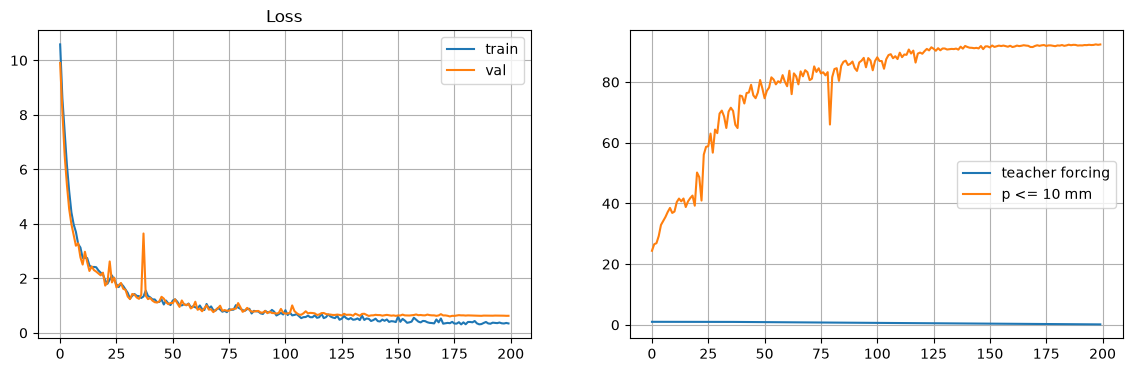

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].legend()
ax[0].grid()
ax[0].set_title("Loss")
ax[1].plot(np.array(history["teacher_forcing_ratio"]), label="teacher forcing")
ax[1].plot([100 * x["p_within_10"] for x in history["val_parts"]], label="p <= 10 mm")
ax[1].legend()
ax[1].grid()
plt.show()

In [18]:
# A: techo del decoder con topología real
out_true = predict_loader(model, test_loader, DEVICE, use_true_transitions=True)
design_true = outputs_to_design(out_true, pre)
# B: inferencia realista con topología predicha
out_real = predict_loader(model, test_loader, DEVICE, use_true_transitions=False)
design_real = outputs_to_design(out_real, pre)

In [19]:
real_eval, pred_true = preparar_para_evaluar(df_test, design_true)
_, pred_real = preparar_para_evaluar(df_test, design_real)
print("TOPOLOGÍA REAL")
metrics_true = evaluar_predicciones(real_eval, pred_true)
print("INFERENCIA REALISTA")
metrics_real = evaluar_predicciones(real_eval, pred_real)

TOPOLOGÍA REAL
Variable   N  MAE_mm  RMSE_mm     R2  pct_5mm  pct_10mm
       g 480   3.073    5.760  0.880   87.500    95.417
       e 480   0.458    1.646  0.916   99.167   100.000
       d 480   1.568    2.567  0.900   93.958    98.542
      Bp 480   5.504    9.730  0.966   69.375    88.125
      tp 480   0.825    2.207  0.828   98.750    99.792
      p1 480   1.970    5.058  0.945   92.708    96.875
      p2 480   3.622    9.210  0.926   88.125    93.958
      p3 472   4.178    8.658  0.970   85.805    93.008
      p4 337   5.186   18.189  0.832   86.053    92.582
      p5 222   4.435   16.126  0.826   89.640    94.595
      p6 143   6.755   21.652  0.820   90.909    93.007
      p7  58  10.603   32.370  0.320   87.931    89.655
      p8  24   7.292   25.021  0.471   87.500    91.667
      p9   4   2.500    5.000  0.852   75.000   100.000
     tws   8   3.750    5.523 -0.856   62.500   100.000
      ts 463   0.646    2.468  0.601   98.056    98.920
     tbs 304   0.773    2.535  0.

In [20]:
print("ESTRUCTURA")
structure = evaluar_estructura(df_test, design_real)
print("SESGO")
display(evaluar_sesgo_p(df_test, design_real).round(2))
print("ERROR ACUMULADO Y")
display(evaluar_acumulado_y(df_test, design_real).round(2))
summary_trans, detail_trans = evaluar_por_transicion(df_test, design_real)
display(summary_trans.round(2))

ESTRUCTURA
n_alma_exacto         0.979167
n_cantonera_exacto    0.922917
ambos_exactos         0.910417
SESGO


,Variable,N,MAE_mm,sesgo_mm,subestimadas_pct,subestimadas_mas_10_pct
0,p1,480,2.49,-0.24,13.75,2.92
1,p2,480,5.73,0.52,21.25,3.33
2,p3,472,6.89,0.59,25.85,6.14
3,p4,337,8.90,-2.15,26.71,8.01
4,p5,222,6.53,-1.83,20.27,5.41
5,p6,143,8.99,-4.15,28.67,6.29
6,p7,58,11.03,-6.72,18.97,8.62
7,p8,24,7.29,-6.46,25.00,8.33
8,p9,4,2.50,-2.50,25.00,0.00


ERROR ACUMULADO Y


,Y_hasta,N,MAE_acumulado_mm,pct_10mm,pct_20mm
0,p1,480,2.49,94.79,97.92
1,p2,480,7.20,89.17,93.12
2,p3,472,9.06,86.23,92.58
3,p4,337,13.13,81.01,89.32
4,p5,222,14.07,74.77,86.49
5,p6,143,16.90,72.03,85.31
6,p7,58,12.95,77.59,89.66
7,p8,24,7.71,79.17,91.67
8,p9,4,10.00,75.00,75.00


,transicion,N,MAE_mm,sesgo_mm,dentro_10_pct,subestimadas_mas_10_pct
10,viga central__viga inferior,194,9.82,1.62,84.54,6.19
12,viga inferior__cantonera primero,217,9.04,-2.96,84.79,11.52
14,viga primero__viga central,194,9.20,3.07,85.05,3.61
4,cantonera primero__cantonera central,58,8.38,-0.59,86.21,6.90
13,viga inferior__inferior,187,5.99,2.35,89.30,3.21
1,cantonera central__cantonera inferior,58,7.26,3.64,89.66,3.45
2,cantonera central__inferior,68,9.04,-8.31,89.71,10.29
11,viga inferior__cantonera central,68,4.63,-3.16,91.18,8.82
3,cantonera inferior__inferior,217,9.21,-8.37,91.24,8.76
5,cantonera primero__cantonera inferior,159,5.43,1.64,91.82,1.26


In [21]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "best_epoch": history["best_epoch"],
        "cat_cardinalities": pre.cat_cardinalities,
        "num_continuous": len(NUMERIC_FEATURES),
        "n_standard_classes": pre.n_standard_classes,
        "hidden_dim": HIDDEN_DIM,
        "num_blocks": NUM_BLOCKS,
        "dropout": DROPOUT,
        "gru_hidden_dim": GRU_HIDDEN_DIM,
    },
    OUTPUT_DIR / "autoregressive_gru_final.pt",
)
joblib.dump(pre, OUTPUT_DIR / "preprocessor_autoregressive.joblib")
design_real.to_parquet(
    OUTPUT_DIR / "test_predictions_autoregressive.parquet", index=False
)